# AdaBoost (Adaptive Boosting)

## ¿Cuál es el objetivo de AdaBoost?

**AdaBoost** (Adaptive Boosting) es un algoritmo de **ensemble** que combina múltiples **clasificadores débiles** (weak classifiers) para crear un **clasificador fuerte**. A diferencia de Random Forest, que entrena árboles **en paralelo** e independientes, AdaBoost los entrena **secuencialmente**: cada nuevo clasificador se enfoca en los errores del anterior.

La idea central es:

1. Entrenar un clasificador débil (típicamente un **decision stump**: un árbol de profundidad 1).
2. **Aumentar el peso** de las muestras que clasificó mal.
3. Entrenar el siguiente clasificador, que ahora se enfocará más en las muestras difíciles.
4. Repetir y combinar todos los clasificadores con un **voto ponderado**.

La predicción final es una **suma ponderada** de todos los clasificadores:

$$
\hat{y} = \text{sign}\left(\sum_{t=1}^{T} \alpha_t \cdot h_t(\mathbf{x})\right)
$$

Donde:

- $h_t(\mathbf{x})$: predicción del clasificador débil $t$ ($-1$ o $+1$).
- $\alpha_t$: **peso** del clasificador $t$ (los más precisos pesan más).
- $T$: número total de clasificadores.

**Random Forest vs AdaBoost:**

| | Random Forest | AdaBoost |
|---|---|---|
| Tipo | Bagging | Boosting |
| Entrenamiento | Paralelo (independiente) | Secuencial (adaptativo) |
| Clasificadores base | Árboles profundos | Clasificadores débiles (stumps) |
| Combinación | Voto igualitario | Voto ponderado ($\alpha_t$) |
| Reduce | Varianza | Sesgo |
| Sensible a ruido | Poco | Más sensible |

**Supongamos un conjunto de datos simples**

Datos en 2D con dos clases ($-1$ y $+1$) que no son separables con una sola línea horizontal o vertical:

| $x_1$ | $x_2$ | Clase ($y$) |
|-------|-------|------|
| 1     | 1     | -1   |
| 2     | 2     | -1   |
| 3     | 1     | +1   |
| 4     | 3     | +1   |
| 5     | 2     | -1   |
| 6     | 4     | +1   |

Un solo decision stump (una sola línea de corte) no puede clasificar bien estos datos. Pero al combinar **varios stumps**, cada uno enfocándose en los errores anteriores, podemos lograr una buena clasificación.

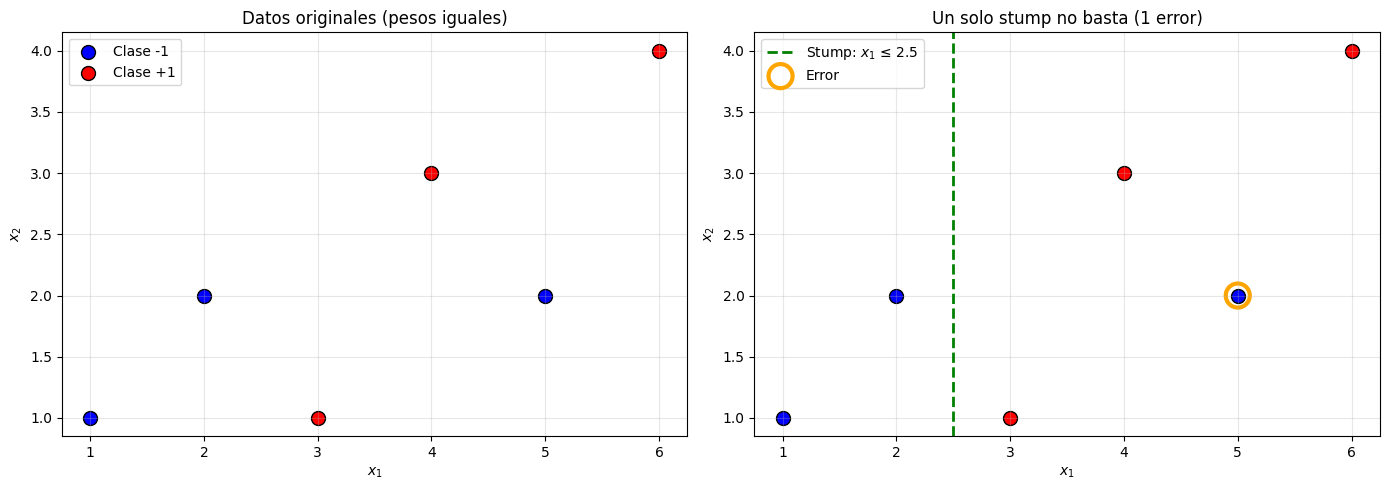

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import warnings

warnings.filterwarnings("ignore", category=SyntaxWarning)

# Datos de ejemplo
X = np.array([[1, 1], [2, 2], [3, 1], [4, 3], [5, 2], [6, 4]])
y = np.array([-1, -1, 1, 1, -1, 1])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel izquierdo: datos con pesos iguales
axes[0].scatter(X[y == -1, 0], X[y == -1, 1], color='blue', s=100,
                label='Clase -1', edgecolors='black')
axes[0].scatter(X[y == 1, 0], X[y == 1, 1], color='red', s=100,
                label='Clase +1', edgecolors='black')
axes[0].set_title('Datos originales (pesos iguales)')
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Panel derecho: un stump no basta
axes[1].scatter(X[y == -1, 0], X[y == -1, 1], color='blue', s=100,
                edgecolors='black')
axes[1].scatter(X[y == 1, 0], X[y == 1, 1], color='red', s=100,
                edgecolors='black')
axes[1].axvline(x=2.5, color='green', linestyle='--', linewidth=2,
                label='Stump: $x_1$ ≤ 2.5')

# Marcar errores
axes[1].scatter([5], [2], s=300, facecolors='none', edgecolors='orange',
                linewidths=3, label='Error')
axes[1].set_title('Un solo stump no basta (1 error)')
axes[1].set_xlabel('$x_1$')
axes[1].set_ylabel('$x_2$')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## ¿Cómo funciona AdaBoost?

AdaBoost funciona de manera **adaptativa**: las muestras mal clasificadas reciben **más peso** para que el siguiente clasificador se enfoque en ellas. Es como un estudiante que, tras un examen, dedica más tiempo a los temas que falló.

Los clasificadores débiles (stumps) son individualmente malos: solo necesitan ser ligeramente **mejores que el azar** (accuracy > 50%). La "magia" de AdaBoost es que al combinar muchos clasificadores débiles de forma inteligente, se obtiene un clasificador fuerte.

## Demostración Matemática

### Paso 1: Inicializar pesos

Cada muestra $\mathbf{x}_i$ comienza con el **mismo peso**:

$$
w_i^{(1)} = \frac{1}{n} \quad \forall i = 1, \dots, n
$$

Donde $n$ es el número total de muestras. Inicialmente, todas las muestras son igual de importantes.

### Paso 2: El clasificador débil (Decision Stump)

Un **decision stump** es el árbol de decisión más simple posible: tiene **un solo split** (profundidad 1).

$$
h(\mathbf{x}) = \begin{cases} +1 & \text{si } p \cdot x_j \geq p \cdot t \\ -1 & \text{si no} \end{cases}
$$

Donde:
- $j$: feature seleccionada.
- $t$: umbral de corte.
- $p \in \{+1, -1\}$: **polaridad** (si la clase +1 está arriba o abajo del umbral).

En cada ronda, el stump busca la combinación $(j, t, p)$ que minimice el **error ponderado**:

$$
\epsilon_t = \sum_{i: h_t(\mathbf{x}_i) \neq y_i} w_i^{(t)}
$$

Notar que es una suma de **pesos**, no un conteo. Las muestras con mayor peso contribuyen más al error.

### Paso 3: Calcular el peso del clasificador ($\alpha_t$)

Una vez entrenado el stump $t$ con error $\epsilon_t$, calculamos su importancia:

$$
\alpha_t = \frac{1}{2} \ln\left(\frac{1 - \epsilon_t}{\epsilon_t}\right)
$$

**Propiedades de $\alpha_t$:**

- Si $\epsilon_t \approx 0$ (clasificador perfecto): $\alpha_t \to +\infty$ (peso muy alto).
- Si $\epsilon_t = 0.5$ (clasificador aleatorio): $\alpha_t = 0$ (sin importancia).
- Si $\epsilon_t > 0.5$ (peor que azar): $\alpha_t < 0$ (invierte las predicciones).

Esto es exactamente lo que queremos: **clasificadores buenos pesan más, clasificadores malos pesan menos** (o se invierten).

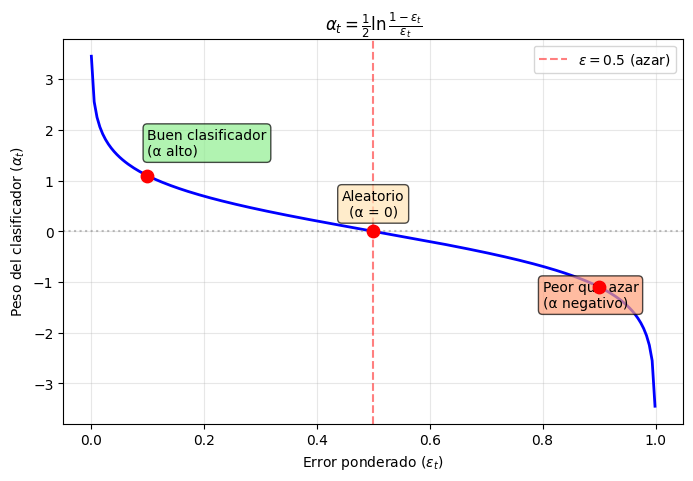

In [2]:
import matplotlib.pyplot as plt
import numpy as np

eps = np.linspace(0.001, 0.999, 200)
alpha = 0.5 * np.log((1 - eps) / eps)

plt.figure(figsize=(8, 5))
plt.plot(eps, alpha, 'b-', linewidth=2)
plt.axhline(y=0, color='gray', linestyle=':', alpha=0.5)
plt.axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='$\epsilon = 0.5$ (azar)')

plt.scatter([0.1, 0.5, 0.9], [0.5*np.log(0.9/0.1), 0, 0.5*np.log(0.1/0.9)],
            color='red', s=80, zorder=5)

plt.annotate('Buen clasificador\n(α alto)', xy=(0.1, 1.5), fontsize=10,
             bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))
plt.annotate('Aleatorio\n(α = 0)', xy=(0.5, 0.3), fontsize=10, ha='center',
             bbox=dict(boxstyle='round', facecolor='moccasin', alpha=0.7))
plt.annotate('Peor que azar\n(α negativo)', xy=(0.8, -1.5), fontsize=10,
             bbox=dict(boxstyle='round', facecolor='lightsalmon', alpha=0.7))

plt.xlabel('Error ponderado ($\epsilon_t$)')
plt.ylabel('Peso del clasificador ($\\alpha_t$)')
plt.title('$\\alpha_t = \\frac{1}{2} \\ln\\frac{1 - \epsilon_t}{\epsilon_t}$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Paso 4: Actualizar los pesos de las muestras

Después de entrenar el clasificador $t$, actualizamos los pesos de las muestras:

$$
w_i^{(t+1)} = w_i^{(t)} \cdot \exp(-\alpha_t \cdot y_i \cdot h_t(\mathbf{x}_i))
$$

Luego normalizamos para que sumen 1:

$$
w_i^{(t+1)} \leftarrow \frac{w_i^{(t+1)}}{\sum_{j=1}^{n} w_j^{(t+1)}}
$$

**¿Qué hace esta fórmula?**

Recordando que $y_i, h_t(\mathbf{x}_i) \in \{-1, +1\}$:

- Si el clasificador **acierta** ($y_i = h_t(\mathbf{x}_i)$): $y_i \cdot h_t = +1$, entonces $\exp(-\alpha_t) < 1$ → peso **disminuye**.
- Si el clasificador **falla** ($y_i \neq h_t(\mathbf{x}_i)$): $y_i \cdot h_t = -1$, entonces $\exp(+\alpha_t) > 1$ → peso **aumenta**.

Así, las muestras mal clasificadas se vuelven más importantes para el siguiente clasificador.

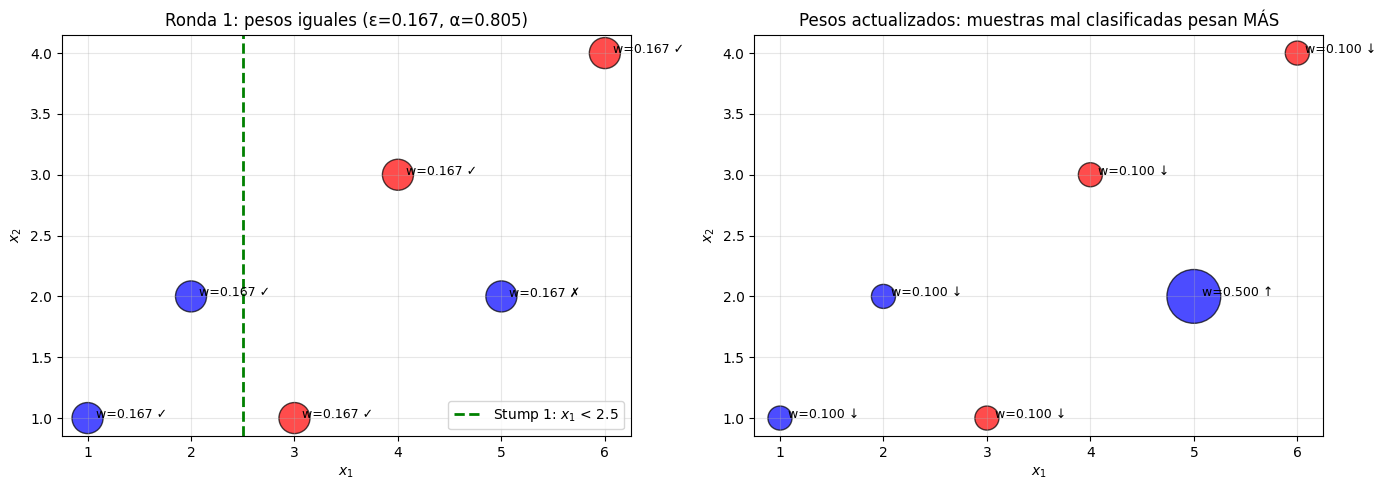

Muestra mal clasificada (x1=5): peso pasó de 0.167 a 0.500 (aumentó)
Muestras bien clasificadas: peso disminuyó


In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Visualización de cómo cambian los pesos
X = np.array([[1, 1], [2, 2], [3, 1], [4, 3], [5, 2], [6, 4]])
y = np.array([-1, -1, 1, 1, -1, 1])
n = len(y)

# Ronda 1: pesos iguales
w = np.full(n, 1/n)

# Stump: x1 < 2.5 → -1, else +1
# Predicciones: [-1, -1, +1, +1, +1, +1]
# Errores: muestra 4 (x1=5, y=-1, pred=+1)
preds_1 = np.array([-1, -1, 1, 1, 1, 1])
misclassified_1 = (preds_1 != y)
eps_1 = np.sum(w[misclassified_1])
alpha_1 = 0.5 * np.log((1 - eps_1) / (eps_1 + 1e-10))

# Actualizar pesos
w_new = w * np.exp(-alpha_1 * y * preds_1)
w_new = w_new / np.sum(w_new)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Antes
colors = ['blue' if yi == -1 else 'red' for yi in y]
axes[0].scatter(X[:, 0], X[:, 1], c=colors, s=w*3000, edgecolors='black', alpha=0.7)
axes[0].axvline(x=2.5, color='green', linestyle='--', linewidth=2, label=f'Stump 1: $x_1$ < 2.5')
for i in range(n):
    marker = '✓' if not misclassified_1[i] else '✗'
    axes[0].annotate(f'  w={w[i]:.3f} {marker}', (X[i,0], X[i,1]), fontsize=9)
axes[0].set_title(f'Ronda 1: pesos iguales (ε={eps_1:.3f}, α={alpha_1:.3f})')
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Después
axes[1].scatter(X[:, 0], X[:, 1], c=colors, s=w_new*3000, edgecolors='black', alpha=0.7)
for i in range(n):
    marker = '↑' if misclassified_1[i] else '↓'
    axes[1].annotate(f'  w={w_new[i]:.3f} {marker}', (X[i,0], X[i,1]), fontsize=9)
axes[1].set_title('Pesos actualizados: muestras mal clasificadas pesan MÁS')
axes[1].set_xlabel('$x_1$')
axes[1].set_ylabel('$x_2$')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Muestra mal clasificada (x1=5): peso pasó de {w[4]:.3f} a {w_new[4]:.3f} (aumentó)")
print(f"Muestras bien clasificadas: peso disminuyó")

### Paso 5: Predicción final

La predicción es una **suma ponderada** de todos los clasificadores:

$$
H(\mathbf{x}) = \text{sign}\left(\sum_{t=1}^{T} \alpha_t \cdot h_t(\mathbf{x})\right)
$$

Los clasificadores con mayor $\alpha_t$ (menor error) tienen más influencia en la decisión final. Es un voto **ponderado por la calidad** de cada clasificador.

### Resumen del algoritmo

**Entrenamiento:**

1. Inicializar pesos: $w_i = 1/n$
2. Para $t = 1, 2, \dots, T$:
   - Entrenar un stump $h_t$ que minimice el error ponderado $\epsilon_t = \sum_{i: h_t(x_i) \neq y_i} w_i$
   - Calcular peso del clasificador: $\alpha_t = \frac{1}{2}\ln\frac{1-\epsilon_t}{\epsilon_t}$
   - Actualizar pesos: $w_i \leftarrow w_i \cdot \exp(-\alpha_t y_i h_t(x_i))$
   - Normalizar pesos: $w_i \leftarrow w_i / \sum_j w_j$

**Predicción:**

$$
\hat{y} = \text{sign}\left(\sum_{t=1}^{T} \alpha_t h_t(\mathbf{x})\right)
$$

### Ejemplo numérico

Usemos nuestro dataset simple con $n = 6$ muestras y $T = 3$ rondas.

**Ronda 1:**

- Pesos iniciales: $w_i = 1/6 \approx 0.167$ para todos.
- Mejor stump: $x_1 < 2.5$ (polaridad +1) → predice $[-1, -1, +1, +1, +1, +1]$.
- Error: muestra 5 ($x_1 = 5$, $y = -1$, pred $= +1$) → $\epsilon_1 = 1/6 \approx 0.167$.
- $\alpha_1 = \frac{1}{2} \ln\frac{1 - 0.167}{0.167} = \frac{1}{2} \ln(5) \approx 0.805$.
- Actualizar pesos: la muestra 5 aumenta, las demás disminuyen.

**Ronda 2:**

- Con los nuevos pesos, el stump se enfoca más en la muestra 5.
- Nuevo stump busca clasificar correctamente esa muestra difícil.

**Ronda 3:**

- Se repite el proceso con los pesos actualizados de la ronda 2.

**Predicción final:**

$$
\hat{y} = \text{sign}(\alpha_1 h_1(\mathbf{x}) + \alpha_2 h_2(\mathbf{x}) + \alpha_3 h_3(\mathbf{x}))
$$

Cada stump contribuye según su $\alpha_t$: los stumps más precisos influyen más.

In [4]:
import numpy as np

X = np.array([[1, 1], [2, 2], [3, 1], [4, 3], [5, 2], [6, 4]], dtype=np.float64)
y = np.array([-1, -1, 1, 1, -1, 1])
n = len(y)

print("=== Ejemplo numérico: AdaBoost paso a paso ===")
print(f"Datos: {n} muestras, 2 features, clases {{-1, +1}}\n")

w = np.full(n, 1/n)

for t in range(3):
    print(f"--- Ronda {t+1} ---")
    print(f"Pesos: [{', '.join(f'{wi:.4f}' for wi in w)}]")

    # Buscar mejor stump
    best_error = float('inf')
    best_feat, best_thresh, best_pol = None, None, None

    for feat_i in range(2):
        thresholds = np.unique(X[:, feat_i])
        for thresh in thresholds:
            for pol in [1, -1]:
                preds = np.ones(n)
                if pol == 1:
                    preds[X[:, feat_i] < thresh] = -1
                else:
                    preds[X[:, feat_i] > thresh] = -1

                error = np.sum(w[preds != y])
                if error < best_error:
                    best_error = error
                    best_feat = feat_i
                    best_thresh = thresh
                    best_pol = pol
                    best_preds = preds.copy()

    alpha = 0.5 * np.log((1 - best_error + 1e-10) / (best_error + 1e-10))

    feat_name = ['x₁', 'x₂'][best_feat]
    op = '<' if best_pol == 1 else '>'
    print(f"Mejor stump: {feat_name} {op} {best_thresh} (polarity={best_pol:+d})")
    print(f"Predicciones: [{', '.join(f'{p:+.0f}' for p in best_preds)}]")
    print(f"Reales:       [{', '.join(f'{yi:+.0f}' for yi in y)}]")

    errors = best_preds != y
    print(f"Errores:      [{', '.join('✗' if e else '✓' for e in errors)}]")
    print(f"ε = {best_error:.4f}, α = {alpha:.4f}")

    # Actualizar pesos
    w = w * np.exp(-alpha * y * best_preds)
    w = w / np.sum(w)
    print()

=== Ejemplo numérico: AdaBoost paso a paso ===
Datos: 6 muestras, 2 features, clases {-1, +1}

--- Ronda 1 ---
Pesos: [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667]
Mejor stump: x₁ < 3.0 (polarity=+1)
Predicciones: [-1, -1, +1, +1, +1, +1]
Reales:       [-1, -1, +1, +1, -1, +1]
Errores:      [✓, ✓, ✓, ✓, ✗, ✓]
ε = 0.1667, α = 0.8047

--- Ronda 2 ---
Pesos: [0.1000, 0.1000, 0.1000, 0.1000, 0.5000, 0.1000]
Mejor stump: x₂ < 3.0 (polarity=+1)
Predicciones: [-1, -1, -1, +1, -1, +1]
Reales:       [-1, -1, +1, +1, -1, +1]
Errores:      [✓, ✓, ✗, ✓, ✓, ✓]
ε = 0.1000, α = 1.0986

--- Ronda 3 ---
Pesos: [0.0556, 0.0556, 0.5000, 0.0556, 0.2778, 0.0556]
Mejor stump: x₁ > 4.0 (polarity=-1)
Predicciones: [+1, +1, +1, +1, -1, -1]
Reales:       [-1, -1, +1, +1, -1, +1]
Errores:      [✗, ✗, ✓, ✓, ✓, ✗]
ε = 0.1667, α = 0.8047



## Implementación con Código

### Funciones

In [5]:
import numpy as np

def train_stump(X, y, w):
    """Entrena el mejor decision stump con pesos"""
    n_samples, n_features = X.shape
    min_error = float('inf')
    best = {'feature': None, 'threshold': None, 'polarity': 1, 'alpha': None}

    for feature_i in range(n_features):
        thresholds = np.unique(X[:, feature_i])
        for threshold in thresholds:
            p = 1
            predictions = np.ones(n_samples)
            predictions[X[:, feature_i] < threshold] = -1

            error = np.sum(w[y != predictions])

            if error > 0.5:
                error = 1 - error
                p = -1

            if error < min_error:
                min_error = error
                best['feature'] = feature_i
                best['threshold'] = threshold
                best['polarity'] = p

    EPS = 1e-10
    best['alpha'] = 0.5 * np.log((1.0 - min_error + EPS) / (min_error + EPS))
    best['error'] = min_error
    return best

def stump_predict(X, stump):
    """Predice con un decision stump"""
    n_samples = X.shape[0]
    X_column = X[:, stump['feature']]
    predictions = np.ones(n_samples)
    if stump['polarity'] == 1:
        predictions[X_column < stump['threshold']] = -1
    else:
        predictions[X_column > stump['threshold']] = -1
    return predictions

def adaboost_fit(X, y, n_clf=5):
    """Entrena AdaBoost"""
    n_samples = X.shape[0]
    w = np.full(n_samples, 1 / n_samples)
    stumps = []

    for _ in range(n_clf):
        stump = train_stump(X, y, w)
        predictions = stump_predict(X, stump)

        w *= np.exp(-stump['alpha'] * y * predictions)
        w /= np.sum(w)

        stumps.append(stump)

    return stumps

def adaboost_predict(X, stumps):
    """Predice con voto ponderado"""
    clf_preds = [s['alpha'] * stump_predict(X, s) for s in stumps]
    y_pred = np.sum(clf_preds, axis=0)
    return np.sign(y_pred)

In [6]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

# Cargar datos
data = datasets.load_breast_cancer()
X, y = data.data, data.target
y[y == 0] = -1  # Convertir a {-1, +1}

# Dividir
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=5
)

# Entrenar
stumps = adaboost_fit(X_train, y_train, n_clf=5)

# Predecir y evaluar
predictions = adaboost_predict(X_test, stumps)
accuracy = np.sum(y_test == predictions) / len(y_test)
print(f"AdaBoost accuracy (5 stumps): {accuracy:.4f}")

# Mostrar los stumps
print(f"\nClasificadores débiles:")
for i, s in enumerate(stumps):
    print(f"  Stump {i+1}: feature {s['feature']}, threshold {s['threshold']:.2f}, "
          f"polarity {s['polarity']:+d}, α = {s['alpha']:.4f}")

AdaBoost accuracy (5 stumps): 0.9737

Clasificadores débiles:
  Stump 1: feature 27, threshold 0.14, polarity -1, α = 1.2272
  Stump 2: feature 23, threshold 728.30, polarity -1, α = 0.9274
  Stump 3: feature 1, threshold 19.98, polarity -1, α = 0.7917
  Stump 4: feature 23, threshold 876.50, polarity -1, α = 0.6100
  Stump 5: feature 26, threshold 0.22, polarity -1, α = 0.5775


### Clase

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


class DecisionStump:
    """Clasificador débil: árbol de profundidad 1"""
    def __init__(self):
        self.polarity = 1
        self.feature_idx = None
        self.threshold = None
        self.alpha = None

    def predict(self, X):
        n_samples = X.shape[0]
        X_column = X[:, self.feature_idx]
        predictions = np.ones(n_samples)
        if self.polarity == 1:
            predictions[X_column < self.threshold] = -1
        else:
            predictions[X_column > self.threshold] = -1
        return predictions


class Adaboost:
    def __init__(self, n_clf=5):
        self.n_clf = n_clf
        self.clfs = []

    def fit(self, X, y):
        """Entrena n_clf clasificadores débiles secuencialmente"""
        n_samples, n_features = X.shape

        # Inicializar pesos
        w = np.full(n_samples, (1 / n_samples))

        self.clfs = []

        for _ in range(self.n_clf):
            clf = DecisionStump()
            min_error = float("inf")

            # Búsqueda greedy del mejor stump
            for feature_i in range(n_features):
                X_column = X[:, feature_i]
                thresholds = np.unique(X_column)

                for threshold in thresholds:
                    p = 1
                    predictions = np.ones(n_samples)
                    predictions[X_column < threshold] = -1

                    misclassified = w[y != predictions]
                    error = sum(misclassified)

                    if error > 0.5:
                        error = 1 - error
                        p = -1

                    if error < min_error:
                        clf.polarity = p
                        clf.threshold = threshold
                        clf.feature_idx = feature_i
                        min_error = error

            # Calcular alpha
            EPS = 1e-10
            clf.alpha = 0.5 * np.log((1.0 - min_error + EPS) / (min_error + EPS))

            # Actualizar pesos
            predictions = clf.predict(X)
            w *= np.exp(-clf.alpha * y * predictions)
            w /= np.sum(w)

            self.clfs.append(clf)

    def predict(self, X):
        """Predice con voto ponderado de todos los clasificadores"""
        clf_preds = [clf.alpha * clf.predict(X) for clf in self.clfs]
        y_pred = np.sum(clf_preds, axis=0)
        return np.sign(y_pred)

    def score(self, X, y):
        """Calcula la accuracy del modelo"""
        predictions = self.predict(X)
        return np.sum(predictions == y) / len(y)

    def plot_stumps(self):
        """Muestra los clasificadores débiles y sus pesos"""
        alphas = [clf.alpha for clf in self.clfs]

        plt.figure(figsize=(8, 4))
        bars = plt.bar(range(1, len(alphas) + 1), alphas, color='steelblue',
                       edgecolor='black', alpha=0.7)
        plt.xlabel('Clasificador débil (stump)')
        plt.ylabel('Peso ($\\alpha_t$)')
        plt.title('Peso de cada clasificador en AdaBoost')
        plt.xticks(range(1, len(alphas) + 1))
        plt.grid(True, alpha=0.3, axis='y')

        for bar, alpha in zip(bars, alphas):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                     f'{alpha:.3f}', ha='center', fontsize=9)
        plt.show()

    def plot_decision_boundary(self, X, y, title="Frontera de decisión - AdaBoost",
                               feature_indices=(0, 1)):
        """Grafica la frontera de decisión usando dos features"""
        i, j = feature_indices
        X_2d = X[:, [i, j]]

        temp = Adaboost(n_clf=self.n_clf)
        temp.fit(X_2d, y)

        h = 0.05
        x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
        y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
        xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                             np.arange(y_min, y_max, h))

        Z = temp.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)

        plt.figure(figsize=(8, 6))
        plt.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(['#AAAAFF', '#FFAAAA']))
        plt.scatter(X_2d[y == -1, 0], X_2d[y == -1, 1], color='blue',
                    edgecolors='k', s=60, label='Clase -1')
        plt.scatter(X_2d[y == 1, 0], X_2d[y == 1, 1], color='red',
                    edgecolors='k', s=60, label='Clase +1')
        plt.xlabel(f'Feature {i}')
        plt.ylabel(f'Feature {j}')
        plt.title(f'{title} ({self.n_clf} stumps)')
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()

AdaBoost accuracy (5 stumps): 0.9737


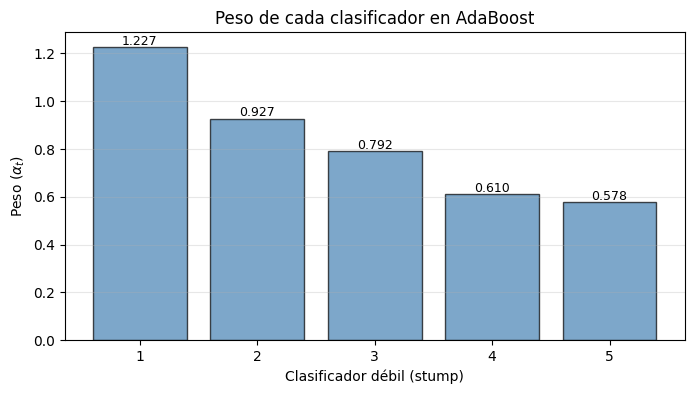

In [8]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

# Cargar datos
data = datasets.load_breast_cancer()
X, y = data.data, data.target
y[y == 0] = -1

# Dividir
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=5
)

# Crear y entrenar modelo
model = Adaboost(n_clf=5)
model.fit(X_train, y_train)

# Evaluar
acc = model.score(X_test, y_test)
print(f"AdaBoost accuracy (5 stumps): {acc:.4f}")

# Visualizar pesos de los clasificadores
model.plot_stumps()

Efecto del número de clasificadores débiles:

  n_clf =  1: accuracy = 0.9123
  n_clf =  3: accuracy = 0.9561
  n_clf =  5: accuracy = 0.9737
  n_clf = 10: accuracy = 0.9649
  n_clf = 20: accuracy = 0.9649
  n_clf = 50: accuracy = 0.9737


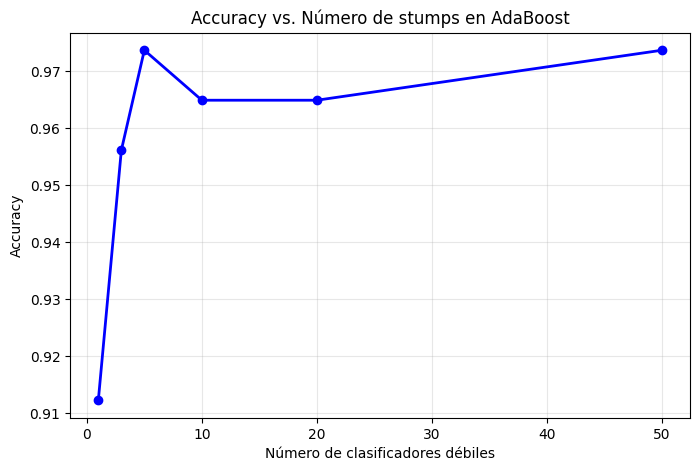

In [9]:
# Comparar diferentes números de clasificadores
print("Efecto del número de clasificadores débiles:\n")
n_clfs = [1, 3, 5, 10, 20, 50]
accs = []

for n_c in n_clfs:
    m = Adaboost(n_clf=n_c)
    m.fit(X_train, y_train)
    a = m.score(X_test, y_test)
    accs.append(a)
    print(f"  n_clf = {n_c:2d}: accuracy = {a:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(n_clfs, accs, 'bo-', linewidth=2)
plt.xlabel('Número de clasificadores débiles')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Número de stumps en AdaBoost')
plt.grid(True, alpha=0.3)
plt.show()

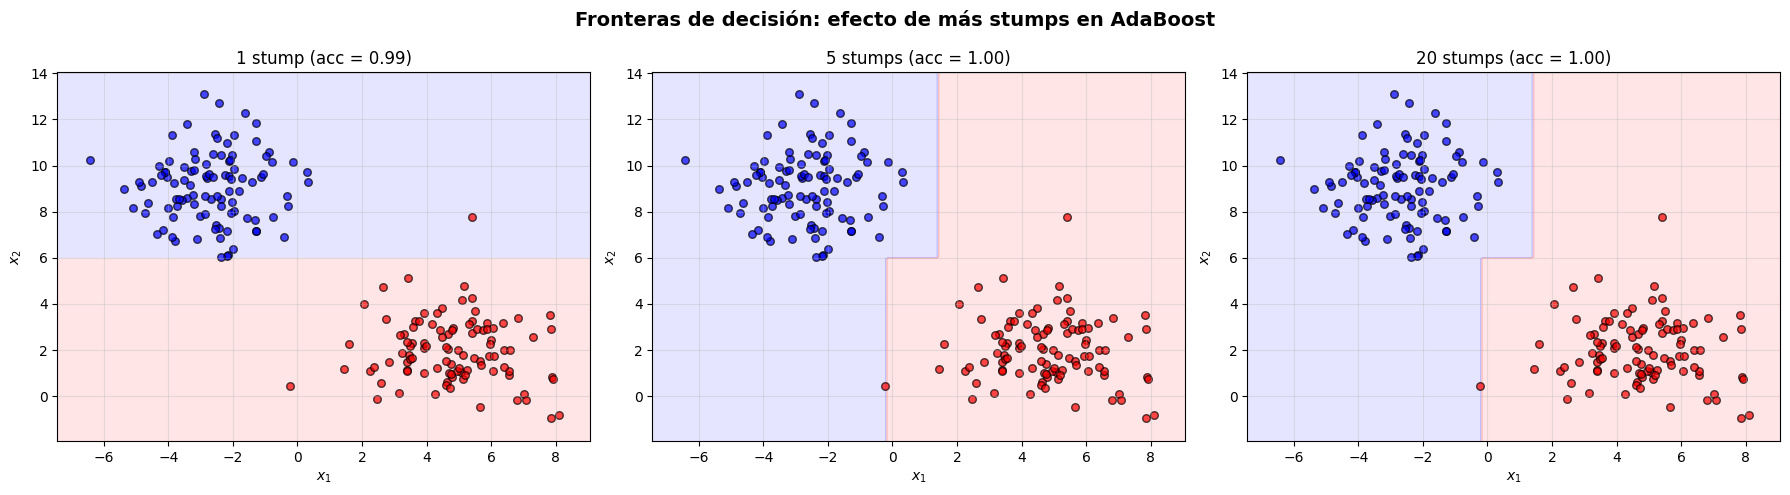

Observar: con más stumps, la frontera se vuelve más compleja y se adapta mejor a los datos.


In [10]:
# Comparación visual: 1 stump vs 5 vs 20
X_vis, y_vis = datasets.make_blobs(
    n_samples=200, n_features=2, centers=2, cluster_std=1.5, random_state=42
)
y_vis[y_vis == 0] = -1

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

configs = [("1 stump", 1), ("5 stumps", 5), ("20 stumps", 20)]

for ax, (title, n_c) in zip(axes, configs):
    m = Adaboost(n_clf=n_c)
    m.fit(X_vis, y_vis)
    a = m.score(X_vis, y_vis)

    h = 0.1
    x_min, x_max = X_vis[:, 0].min() - 1, X_vis[:, 0].max() + 1
    y_min, y_max = X_vis[:, 1].min() - 1, X_vis[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(['#AAAAFF', '#FFAAAA']))
    ax.scatter(X_vis[y_vis == -1, 0], X_vis[y_vis == -1, 1], color='blue',
               edgecolors='k', s=30, alpha=0.7)
    ax.scatter(X_vis[y_vis == 1, 0], X_vis[y_vis == 1, 1], color='red',
               edgecolors='k', s=30, alpha=0.7)
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_title(f'{title} (acc = {a:.2f})')
    ax.grid(True, alpha=0.3)

plt.suptitle('Fronteras de decisión: efecto de más stumps en AdaBoost',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Observar: con más stumps, la frontera se vuelve más compleja y se adapta mejor a los datos.")